##  CMF-BO-GP 1.0
### Function 1 - Radiation Field

Detect likely contamination sources in a two-dimensional area, 
such as a radiation field, where only proximity yields a non-zero reading. 
The system uses Bayesian optimisation to tune detection parameters and reliably identify both strong and weak sources.

Challenge - readings are zero across most of your grid, creating a highly sparse, non-linear search space.
The "Zero-Reading" Dead Zone: If your sensor is outside the radiation radius, the gradient is exactly zero. 
Standard gradient-descent algorithms will fail because they cannot determine which direction to move


### Components to the model
#### 1. Import libraries
#### 2. Import and Analyse data - combining baseline data with new queries; then performing statistical analysis on the combined data
#### 3. Visualising data - create a 2D view with showing baseline, additional queries and current maxima - and a 3D representation.
#### 4. Core Model - v0 - simple UCB with proximity restrictor
#### 5. Expliotation model - for final queries to maximise outputs (from scipy.optimize import minimize)

In [14]:
# ==============================================
# 1. Import required libraries to support model
# ==============================================

import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from IPython.display import clear_output
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.gaussian_process.kernels import Matern
from scipy.stats import norm
from scipy.interpolate import griddata


In [15]:
# ====================================
# 2. Import and Analyse the data set  
# ====================================

# Your 2D spatial coordinate data (10 positions)
inputs = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC1/initial_inputs.npy')
output = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC1/initial_outputs.npy')

print(f"Base Maximia: {output.max().item():.8f}")

extra_inputs = [[0.650114, 0.681526],[0.585859,0.565657],[0.616162, 0.646465],
                [0.626263, 0.646465],[0.626263, 0.636364],[0.626263, 0.626263],
               [0.626263, 0.636360],[0.595960, 0.626263],[0.656566, 0.626263],
                [0.626263, 0.606061],[0.646465, 0.646465],[0.626263, 0.626263]]
               
extra_output = [-0.003606219797145482,0.00002136507463814,0.6208417126227237,
                0.8904218694712779,1.7039621839197536,1.9508262577165927,
                1.7042210119222299,0.09557699440564725,0.24437401965527514,
               	0.5476324201332434,	0.40641810232795594,1.9508262577165927]

inputs = np.vstack([inputs, extra_inputs])
output = np.append(output, extra_output)

print(f"Current Maxima: {output.max().item():.8f}")

# Combine into a single Pandas DataFrame
df = pd.DataFrame(inputs, columns=['Input_Y', 'Input_Z'])
df['Output_Target'] = output

# Compute the correlation matrix
# Change method to 'spearman' if relationships are non-linear curves
corr_matrix = df.corr(method='pearson')

# Isolate how each input correlates *only* with the target output
target_corr = corr_matrix['Output_Target'].drop('Output_Target')

print("Correlation with Output:")
print(target_corr)

# Calculate non-linear relationship dependency (higher score = stronger relationship)
mi_scores = mutual_info_regression(inputs, output)

for name, score in zip(['Input_Y', 'Input_Z'], mi_scores):
    print(f"{name} Mutual Information Score: {score:.4f}")

# Fit a quick non-linear model that checks all 3 dimensions simultaneously
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(inputs, output)

# Extract total feature importances (including interactions)
importances = model.feature_importances_

for name, score in zip(['Input_Y', 'Input_Z'], importances):
    print(f"{name} Total Importance (with interactions): {score:.4f}")

Base Maximia: 0.00000000
Current Maxima: 1.95082626
Correlation with Output:
Input_Y    0.140771
Input_Z    0.146301
Name: Output_Target, dtype: float64
Input_Y Mutual Information Score: 0.0000
Input_Z Mutual Information Score: 0.1388
Input_Y Total Importance (with interactions): 0.5859
Input_Z Total Importance (with interactions): 0.4141


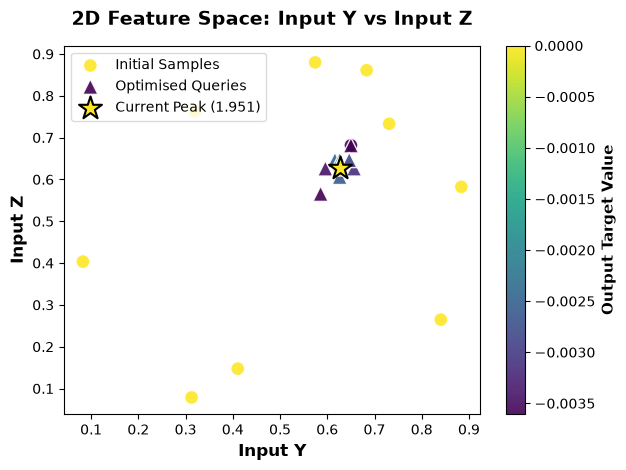

In [16]:
# ===================================
# 3.1 Visualise the data set Y and Z
# ===================================

# Find the coordinates of the maximum value dynamically
max_row_index = df['Output_Target'].idxmax()
max_y = df.loc[max_row_index, 'Input_Y']
max_z = df.loc[max_row_index, 'Input_Z']
max_val = df.loc[max_row_index, 'Output_Target']


# Create scatter plot with the first 10 smaples
scatter1 = plt.scatter(
    data=df.iloc[:10], 
    x='Input_Y', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=100,            # Marker size
    edgecolor='w',    # White border around markers
    alpha=0.9
)

# Plot the next query samples (e.g., as triangles '^')
scatter2 = plt.scatter(
    data=df.iloc[10:len(output)], 
    x='Input_Y', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=120,            # Made slightly larger so triangles stand out nicely
    edgecolor='w',    
    alpha=0.9,
    marker='^',       # <--- Shape for the next points
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max()
)

scatter3 = plt.scatter(
    x=max_y, 
    y=max_z, 
    c=[max_val],   
    cmap='viridis',    # Highly visible contrasting color
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max(),
    s=300,            # Much larger marker size to make it pop
    marker='*',       # Star shape
    edgecolor='black',
    linewidth=1.5,
    label=f'Current Max ({max_val:.2f})',
    zorder=5          # Ensures it sits on top of all other points
)


# Add elements
cbar = plt.colorbar(scatter1)
cbar.set_label('Output Target Value', fontsize=11, fontweight='bold')
plt.xlabel('Input Y', fontsize=12, fontweight='bold')
plt.ylabel('Input Z', fontsize=12, fontweight='bold')
plt.title('2D Feature Space: Input Y vs Input Z', fontsize=14, fontweight='bold', pad=15)

plt.legend(
    handles=[scatter1, scatter2,scatter3], 
    labels=['Initial Samples', 'Optimised Queries', f'Current Peak ({max_val:.3f})'],
    loc='upper left', 
    frameon=True, 
    facecolor='white', 
    edgecolor='lightgray', 
    fontsize=10
)
plt.tight_layout()
plt.show()

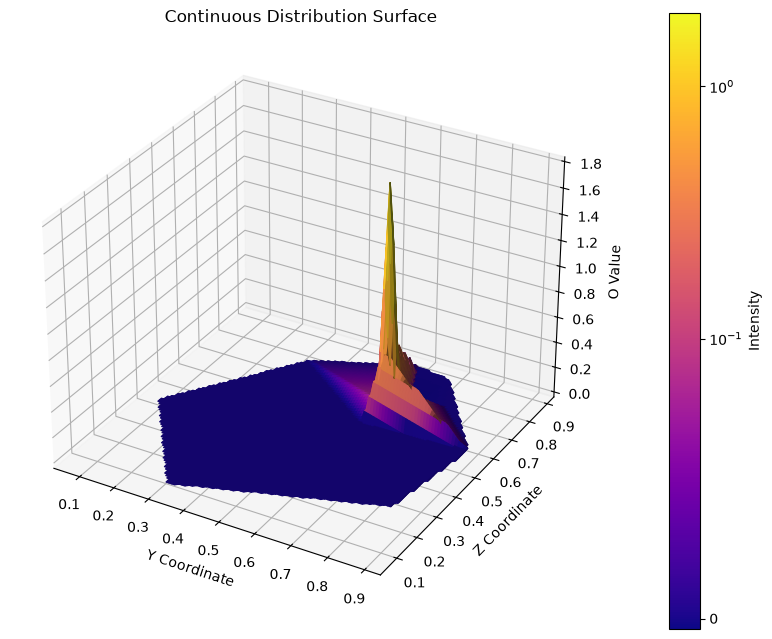

In [18]:
# ===================================
# 3.2 Visualise the data set 3D
# ===================================


coords = (inputs[:,0],inputs[:,1])

# Define a regular 2D grid based on your data boundaries
grid_x, grid_y = np.meshgrid(
    np.linspace(coords[0].min(), coords[0].max(), 100),
    np.linspace(coords[1].min(), coords[1].max(), 100)
)

# Interpolate the scattered (x, y, z) data onto the uniform grid
# Options for method: 'linear', 'cubic', or 'nearest'
grid_z = griddata((coords[0], coords[1]), output, (grid_x, grid_y), method='linear')

# If your y_clean variable is different from values, interpolate it too for the colors
grid_color = griddata((coords[0], coords[1]), output, (grid_x, grid_y), method='linear')

# Create the 3D surface plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
norm = colors.SymLogNorm(linthresh=0.1, vmin=output.min(), vmax=output.max())


# Plot the continuous surface
# facecolors overrides standard mapping to use your output
surf = ax.plot_surface(
    grid_x, grid_y, grid_z,
    facecolors=plt.cm.plasma(norm(grid_color)),
    rcount=100, ccount=100,  # Grid resolution
    antialiased=True,
    shade=True
)

# Design elements
# Create a dummy scalar mappable object just to display the colorbar correctly
mappable = plt.cm.ScalarMappable(cmap='plasma', norm=norm)
fig.colorbar(mappable, ax=ax, label="Intensity", pad=0.1)

ax.set_xlabel("Y Coordinate")
ax.set_ylabel("Z Coordinate")
ax.set_zlabel("O Value")
ax.set_title("Continuous Distribution Surface")

plt.show()

In [27]:
# ===========================================
# 4 (v0) Simple Model - with Proximity Radius
# ===========================================

# 1. Preprocessing Log-Transform the Target Space
 # Initialize
X_samples = inputs
y_samples = output
init_length_scales = [0.1, 0.1]

# 2. Fit the Gaussian Process Regressor
# A Matérn kernel allows the model to capture sharp, localized spikes.
kernel = Matern(length_scale=init_length_scales, length_scale_bounds=(0.001, 1.0), nu=0.5)

gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-5,normalize_y=True, n_restarts_optimizer=15)
gp.fit(X_samples, y_samples)

# 3. Define a High-Variance (Exploratory) Acquisition Function
def high_variance_ucb(X_grid, gp_model, beta=20.0):
    """
    Acquisition Function: UCB = Mean + beta * Standard Deviation
    Setting beta high (e.g., 5.0 to 20.0) forces the search to focus on 
    high-variance unmapped zones rather than exploiting existing peaks.
    """
    mean, std = gp_model.predict(X_grid, return_std=True)
    return mean + (beta * std)

# 4. Define restricted physical movement radius (on a 0 to 1 normalized scale)
# For example: 0.1 means you can move at most 10% of the map's width per step
PROXIMITY_RADIUS = 0.05  

# 5. Identify where your sampler is physically located right now (the last row of coords)
current_position = inputs[-1] 

# 6.Generate the search grid
x_span = np.linspace(0.0, 1.0, 100)
y_span = np.linspace(0.0, 1.0, 100)
X_mesh, Y_mesh = np.meshgrid(x_span, y_span)
grid_points = np.c_[X_mesh.ravel(), Y_mesh.ravel()]


# 7. Calculate the straight-line distance from current_position to every point on the grid
distances = np.linalg.norm(grid_points - current_position, axis=1)

# 8. Create a boolean mask: True for points within the allowed radius
# Evaluate the acquisition values across the entire map
valid_radius_mask = distances <= PROXIMITY_RADIUS
acq_values = high_variance_ucb(grid_points, gp, beta=20.0)

# 9. Set the acquisition value of ALL points OUTSIDE your radius to a massive negative number
# This guarantees np.argmax will never pick them, without ruining the data for your plot
acq_values_constrained = np.copy(acq_values)
acq_values_constrained[~valid_radius_mask] = -1e10

# 9. Reshape the unconstrained values for the plotting mesh
# Find the absolute best coordinate point *strictly within your radius*
acq_grid = acq_values.reshape(X_mesh.shape)
best_idx = np.argmax(acq_values_constrained)
next_query_point = grid_points[best_idx]

print(f"Current Position: {current_position}")
print(f"Constrained Next Point (Within Radius {PROXIMITY_RADIUS}): {next_query_point}")


Current Position: [0.626263 0.626263]
Constrained Next Point (Within Radius 0.05): [0.64646465 0.58585859]


In [20]:
# ============================================
# 5. Exploitation Model - scipy.optimize
# ============================================


## import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C
from scipy.optimize import minimize

# 1. Load the 2D dataset (Features: Y, Z)
X_train = inputs
y_train = output

# 2. Configure a Matern GP Surrogate Model
# Matern nu=1.5 allows for the distinct "cliffs"
kernel = C(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(2), length_scale_bounds=(1e-2, 10.0), nu=1.5)
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=25, alpha=1e-6, random_state=42)

# Fit model to historical space
gp.fit(X_train, y_train)

# 3. Formulate Optimization Target (Negative prediction for minimization algorithm)
def objective(x):
    # Predict returns shape (1, 3), flatten to extract scalar
    return -float(gp.predict(x.reshape(1, -1))[0])

# 4. Enforce Bounding Box System limits [0.0, 1.0]
bounds = [
    (0.60, 0.7),  # Y
    (0.60, 0.7)   # Z
]

# 5. Use your historical peak coordinate as the optimization warm-start point
x_start = np.array([ 0.626263, 0.626263])

# 6. Execute L-BFGS-B Optimization Local Search
result = minimize(objective, x_start, method='L-BFGS-B', bounds=bounds)

# 7. Display Predicted Coordinates
print("--- GAUSSIAN PROCESS TARGET PREDICTION ---")
print(f"Predicted Max Output: {abs(result.fun):.4f}")
print("Optimal Coordinates:")
for name, val in zip(['Y', 'Z'], result.x):
    print(f"  Input_{name}: {val:.6f}")


--- GAUSSIAN PROCESS TARGET PREDICTION ---
Predicted Max Output: 1.9789
Optimal Coordinates:
  Input_Y: 0.626463
  Input_Z: 0.628408
